# Don't Miss the Battery: Faster R-CNN baseline (E1) + first safety metrics (E2 preview)
**Bhoomika Lnu, Group 3, DATA-255**

Steps: download RecyBat24, EDA, leak-free val/test split, fine-tune Faster R-CNN ResNet-50-FPN,
COCO metrics, then a threshold sweep for missed-battery rate at precision 0.90 and cost-weighted error.

**Before running:** Runtime > Change runtime type > T4 GPU. Then Runtime > Run all.
The Drive mount cell asks for permission once. Checkpoints go to Drive, so if Colab disconnects,
just Run all again and training resumes from the last epoch.

In [1]:
# ---- Config ----
SEED = 42
EPOCHS = 6           # ~2.5 min/epoch on a T4; val mAP plateaued by epoch 4-6 in the first run
BATCH_SIZE = 4
LR = 0.005           # linear scaling of torchvision's 0.02 @ batch 16
IMG_SIZE = 640       # RecyBat24 images are 640x640
IOU_MATCH = 0.5      # IoU for counting a battery as "caught"
TARGET_PRECISION = 0.90
MISS_COST = 10       # a miss costs 10x a false alarm
DATA_URL = "https://zenodo.org/api/records/15490523/files/recybat24.tar.gz/content"
ROOT = "/content/recybat24"

import os, sys, json, random, time, glob, re, tarfile, math, contextlib, io, urllib.request
from collections import defaultdict, Counter
import numpy as np
import torch, torchvision
import matplotlib.pyplot as plt

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", dev)
if dev.type == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device cuda
Tesla T4


In [2]:
# ---- Output folder on Google Drive (survives disconnects) ----
# If the Drive mount fails or is declined, outputs stay in Colab's local disk and are zipped for download
# at the end; only resume-after-disconnect is lost.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/dont_miss_the_battery/frcnn_baseline_v2"   # v2: fresh folder, old run used wrong labels
except ImportError:
    OUT = "./outputs/frcnn_baseline_v2"
except Exception as e:
    print(f"Drive mount failed ({e}); saving locally instead. Results will be downloaded as a zip at the end.")
    OUT = "/content/outputs/frcnn_baseline_v2"
os.makedirs(OUT, exist_ok=True)
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
print("Outputs ->", OUT)

Mounted at /content/drive
Outputs -> /content/drive/MyDrive/dont_miss_the_battery/frcnn_baseline_v2


In [3]:
# ---- Download + extract RecyBat24 (Zenodo record 15490523, CC BY-NC-ND 4.0) ----
if not os.path.exists(os.path.join(ROOT, ".done")):
    os.makedirs(ROOT, exist_ok=True)
    tgz = "/content/recybat24.tar.gz"
    if not os.path.exists(tgz):
        print("Downloading ~263 MB ...")
        urllib.request.urlretrieve(DATA_URL, tgz)
    with tarfile.open(tgz) as t:
        try:
            t.extractall(ROOT, filter="data")
        except TypeError:
            t.extractall(ROOT)
    open(os.path.join(ROOT, ".done"), "w").close()

# Show the folder layout (2 levels) so we know what we got
for dirpath, dirnames, filenames in os.walk(ROOT):
    depth = dirpath[len(ROOT):].count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(dirpath) + f"/  ({len(filenames)} files)")

recybat24/  (1 files)
  recybat24/  (0 files)
    val/  (1409 files)
    train/  (1423 files)


In [4]:
# ---- Find the COCO annotation files ----
coco_files = {}
for p in glob.glob(ROOT + "/**/*.json", recursive=True):
    try:
        d = json.load(open(p))
    except Exception:
        continue
    if isinstance(d, dict) and {"images", "annotations", "categories"} <= d.keys():
        print(p, "| images:", len(d["images"]), "| boxes:", len(d["annotations"]))
        low = p.lower()
        if "segmentation" in os.path.basename(low):
            continue    # instance-seg file repeats every battery 3x; use the detection annotations.json
        if "train" in low:
            coco_files["train"] = p
        elif "val" in low:
            coco_files["val"] = p
        elif "test" in low:
            coco_files["test"] = p
assert "train" in coco_files and "val" in coco_files, f"Could not identify train/val json: {coco_files}"
coco = {k: json.load(open(v)) for k, v in coco_files.items()}

# Index every image file by basename so file_name in the json can be resolved
img_index = defaultdict(list)
for p in glob.glob(ROOT + "/**/*", recursive=True):
    if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
        img_index[os.path.basename(p)].append(p)

def resolve(file_name, split):
    direct = os.path.join(os.path.dirname(coco_files[split]), file_name)
    if os.path.exists(direct):
        return direct
    cands = img_index.get(os.path.basename(file_name), [])
    if not cands:
        raise FileNotFoundError(file_name)
    for c in cands:
        if split in c.lower():
            return c
    return cands[0]

# Categories: keep only those that actually have boxes (drops empty parent categories)
used = sorted({a["category_id"] for s in coco.values() for a in s["annotations"]})
cat_names = {c["id"]: c["name"] for c in coco["train"]["categories"]}
cat2label = {cid: i + 1 for i, cid in enumerate(used)}            # 0 = background
CLASSES = ["__background__"] + [cat_names.get(cid, str(cid)) for cid in used]
K = len(CLASSES) - 1
print("Classes:", CLASSES[1:])

/content/recybat24/recybat24/val/annotations.json | images: 1407 | boxes: 1434
/content/recybat24/recybat24/val/instance_segmentation_annotations.json | images: 1407 | boxes: 4302
/content/recybat24/recybat24/train/annotations.json | images: 1421 | boxes: 1437
/content/recybat24/recybat24/train/instance_segmentation_annotations.json | images: 1421 | boxes: 4311
Classes: ['cylindric', 'pouch', 'prismatic']


val {'images': 1407, 'boxes': 1434, 'per_class': {'cylindric': 234, 'pouch': 870, 'prismatic': 330}, 'boxes_per_image_mean': 1.019189765458422}
train {'images': 1421, 'boxes': 1437, 'per_class': {'cylindric': 239, 'pouch': 868, 'prismatic': 330}, 'boxes_per_image_mean': 1.011259676284307}


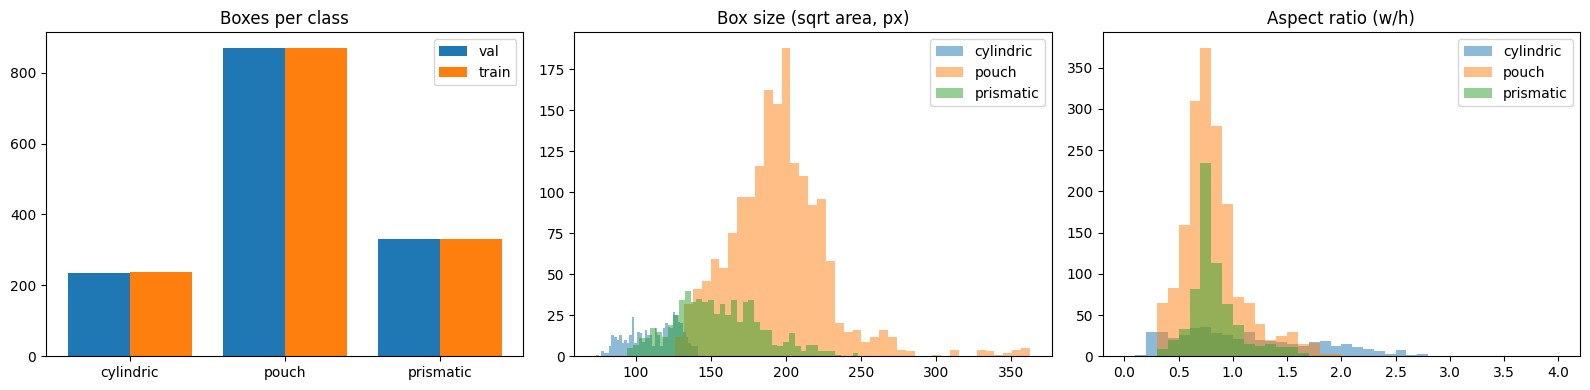

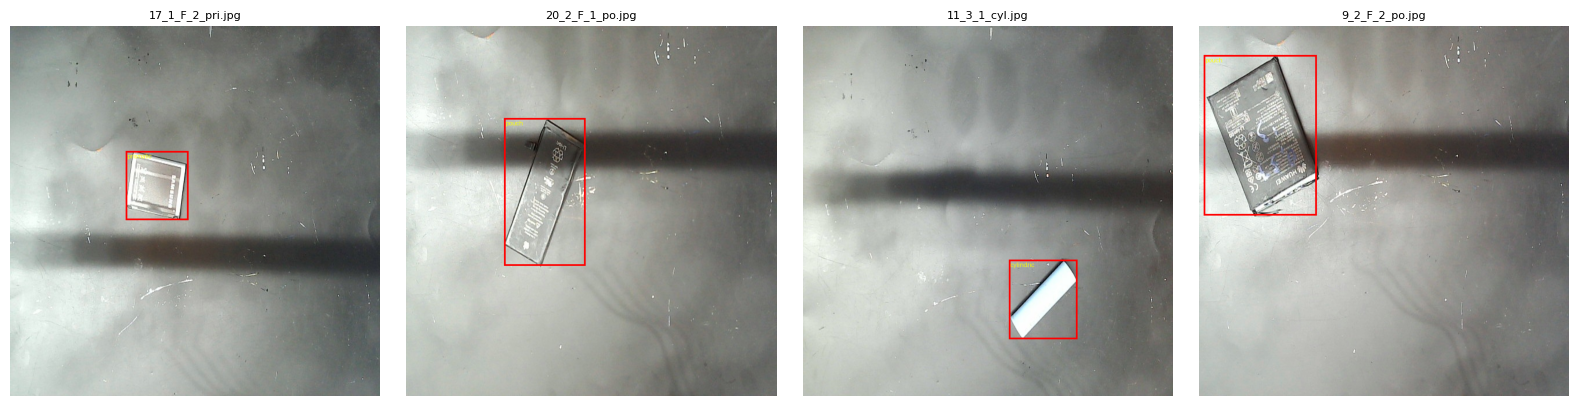

In [5]:
# ---- EDA ----
def split_stats(d):
    per_img = Counter(a["image_id"] for a in d["annotations"])
    cls = Counter(CLASSES[cat2label[a["category_id"]]] for a in d["annotations"])
    return per_img, cls

eda = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for split, d in coco.items():
    per_img, cls = split_stats(d)
    eda[split] = {"images": len(d["images"]), "boxes": len(d["annotations"]), "per_class": dict(cls),
                  "boxes_per_image_mean": float(np.mean([per_img.get(i["id"], 0) for i in d["images"]]))}
    print(split, eda[split])
names = CLASSES[1:]
x = np.arange(K); w = 0.8 / len(coco)
for j, split in enumerate(coco):
    axes[0].bar(x + j * w, [eda[split]["per_class"].get(n, 0) for n in names], w, label=split)
axes[0].set_xticks(x + w * (len(coco) - 1) / 2); axes[0].set_xticklabels(names)
axes[0].set_title("Boxes per class"); axes[0].legend()

allann = [a for d in coco.values() for a in d["annotations"]]
for n in names:
    sel = [a for a in allann if CLASSES[cat2label[a["category_id"]]] == n]
    axes[1].hist([math.sqrt(a["bbox"][2] * a["bbox"][3]) for a in sel], bins=40, alpha=0.5, label=n)
    axes[2].hist([a["bbox"][2] / max(a["bbox"][3], 1e-6) for a in sel], bins=40, alpha=0.5, label=n, range=(0, 4))
axes[1].set_title("Box size (sqrt area, px)"); axes[1].legend()
axes[2].set_title("Aspect ratio (w/h)"); axes[2].legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG, "eda.png"), dpi=120); plt.show()

# A few sample images with boxes
from PIL import Image, ImageDraw
samp = random.sample(coco["train"]["images"], 4)
anns_by_img = defaultdict(list)
for a in coco["train"]["annotations"]:
    anns_by_img[a["image_id"]].append(a)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, info in zip(axes, samp):
    im = Image.open(resolve(info["file_name"], "train")).convert("RGB"); dr = ImageDraw.Draw(im)
    for a in anns_by_img[info["id"]]:
        bx, by, bw, bh = a["bbox"]; dr.rectangle([bx, by, bx + bw, by + bh], outline="red", width=3)
        dr.text((bx + 3, by + 3), CLASSES[cat2label[a["category_id"]]], fill="yellow")
    ax.imshow(im); ax.axis("off"); ax.set_title(os.path.basename(info["file_name"])[:30], fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "samples.png"), dpi=100); plt.show()

In [6]:
# ---- Leak-free split: released val -> val + test, grouped by battery ID ----
# File names: 26_2_3_cyl.jpg (cylindric) or 42_5_F_2_po.jpg (pouch/prismatic, F/R = front/rear side;
# train holds the F side, val the R side). Battery numbers restart per type, so the ID is number + type.
# All capture groups are joined. Each battery has ~15 images.
GROUP_REGEX = r"^(\d+)_\d+_(?:[A-Za-z]_)?\d+_([A-Za-z]+)"

val_imgs = coco["val"]["images"]
print("Sample val file names:")
for i in val_imgs[:15]:
    print("  ", i["file_name"])

def battery_id(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    stem = re.sub(r"\.rf\.[0-9a-f]+$", "", stem)        # Roboflow export hash, if any
    if GROUP_REGEX:
        m = re.search(GROUP_REGEX, stem)
        if m:
            return "_".join(m.groups())
    return re.sub(r"[_\-\s]*\d+$", "", stem) or stem     # default: drop trailing frame number

groups = [battery_id(i["file_name"]) for i in val_imgs]
n_groups = len(set(groups))
print(f"{len(val_imgs)} val images -> {n_groups} battery groups")

from sklearn.model_selection import StratifiedGroupKFold
if 2 <= n_groups <= len(val_imgs) / 1.5:
    # 50/50 by battery, stratified by battery type so the few cylindric batteries land on both sides
    types = [g.rsplit("_", 1)[-1] for g in groups]
    sgkf = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
    vi, ti = next(sgkf.split(val_imgs, types, groups=groups))
    SPLIT_MODE = "grouped by battery ID"
else:
    print("WARNING: file names do not reveal a battery ID; falling back to a random 50/50 split. "
          "Set GROUP_REGEX and re-run for a leak-free split.")
    idx = np.random.RandomState(SEED).permutation(len(val_imgs)); vi, ti = idx[: len(idx) // 2], idx[len(idx) // 2:]
    SPLIT_MODE = "random (no battery ID found)"
val_ids = [val_imgs[i]["id"] for i in vi]
test_ids = [val_imgs[i]["id"] for i in ti]
assert not ({groups[i] for i in vi} & {groups[i] for i in ti}) or SPLIT_MODE.startswith("random")
print(f"Split mode: {SPLIT_MODE} | val {len(val_ids)} imgs | test {len(test_ids)} imgs")
train_groups = {battery_id(i["file_name"]) for i in coco["train"]["images"]}
test_groups = {groups[i] for i in ti}
print(f"Batteries: train {len(train_groups)} | val {len({groups[i] for i in vi})} | test {len(test_groups)} | "
      f"test batteries also seen (other side) in train: {len(train_groups & test_groups)}")
json.dump({"mode": SPLIT_MODE, "val_ids": val_ids, "test_ids": test_ids, "seed": SEED},
          open(os.path.join(OUT, "split.json"), "w"))

Sample val file names:
   26_2_3_cyl.jpg
   26_1_2_cyl.jpg
   19_2_1_cyl.jpg
   19_1_1_cyl.jpg
   26_4_2_cyl.jpg
   24_1_1_cyl.jpg
   24_2_2_cyl.jpg
   17_4_3_cyl.jpg
   20_4_1_cyl.jpg
   16_4_2_cyl.jpg
   22_4_1_cyl.jpg
   25_1_1_cyl.jpg
   29_2_3_cyl.jpg
   16_1_2_cyl.jpg
   19_3_1_cyl.jpg
1407 val images -> 94 battery groups
Split mode: grouped by battery ID | val 702 imgs | test 705 imgs
Batteries: train 95 | val 47 | test 47 | test batteries also seen (other side) in train: 42


In [7]:
# ---- Dataset ----
from torchvision.io import read_image, ImageReadMode

class BatteryDet(torch.utils.data.Dataset):
    def __init__(self, split, img_ids=None, train=False):
        d = coco[split]
        self.split, self.train = split, train
        self.imgs = {i["id"]: i for i in d["images"]}
        self.ids = list(img_ids) if img_ids is not None else list(self.imgs)
        self.anns = defaultdict(list)
        for a in d["annotations"]:
            self.anns[a["image_id"]].append(a)

    def __len__(self):
        return len(self.ids)

    def gt(self, iid):
        boxes, labels = [], []
        for a in self.anns[iid]:
            x, y, w, h = a["bbox"]
            if w >= 1 and h >= 1:
                boxes.append([x, y, x + w, y + h]); labels.append(cat2label[a["category_id"]])
        return np.array(boxes, np.float32).reshape(-1, 4), np.array(labels, np.int64)

    def __getitem__(self, i):
        iid = self.ids[i]
        img = read_image(resolve(self.imgs[iid]["file_name"], self.split), ImageReadMode.RGB).float() / 255
        boxes, labels = self.gt(iid)
        boxes = torch.from_numpy(boxes)
        if self.train and random.random() < 0.5:
            img = img.flip(-1)
            W = img.shape[-1]
            boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        return img, {"boxes": boxes, "labels": torch.from_numpy(labels), "image_id": torch.tensor(iid)}

def collate(b):
    return tuple(zip(*b))

train_ds = BatteryDet("train", train=True)
val_ds = BatteryDet("val", val_ids)
test_ds = BatteryDet("val", test_ids)
g = torch.Generator().manual_seed(SEED)
train_loader = torch.utils.data.DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=2,
                                           collate_fn=collate, generator=g, drop_last=True)
print(len(train_ds), len(val_ds), len(test_ds))

1421 702 705


In [8]:
# ---- Model: COCO-pretrained Faster R-CNN ResNet-50-FPN, new head for K battery classes ----
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def build_model():
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
                                min_size=IMG_SIZE, max_size=IMG_SIZE)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, K + 1)
    m.roi_heads.score_thresh = 0.001       # keep low-score boxes for mAP and threshold sweeps
    m.roi_heads.detections_per_img = 100
    return m.to(dev)

model = build_model()
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params / 1e6:.1f} M")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 192MB/s]


Parameters: 41.3 M


In [9]:
# ---- COCO evaluation helpers ----
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def make_gt(ds):
    images, anns = [], []
    for iid in ds.ids:
        info = ds.imgs[iid]
        images.append({"id": iid, "width": info.get("width", IMG_SIZE), "height": info.get("height", IMG_SIZE)})
        b, l = ds.gt(iid)
        for bb, ll in zip(b, l):
            w, h = float(bb[2] - bb[0]), float(bb[3] - bb[1])
            anns.append({"id": len(anns) + 1, "image_id": iid, "category_id": int(ll),
                         "bbox": [float(bb[0]), float(bb[1]), w, h], "area": w * h, "iscrowd": 0})
    c = COCO()
    c.dataset = {"images": images, "annotations": anns,
                 "categories": [{"id": i, "name": n} for i, n in enumerate(CLASSES) if i > 0]}
    with contextlib.redirect_stdout(io.StringIO()):
        c.createIndex()
    return c

@torch.no_grad()
def predict(model, ds, bs=8):
    model.eval()
    loader = torch.utils.data.DataLoader(ds, bs, shuffle=False, num_workers=2, collate_fn=collate)
    preds = {}
    for imgs, tgts in loader:
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            out = model([im.to(dev) for im in imgs])
        for t, o in zip(tgts, out):
            preds[int(t["image_id"])] = {k: v.float().cpu().numpy() for k, v in o.items()}
    return preds

def coco_metrics(preds, gt, verbose=False):
    res = [{"image_id": iid, "category_id": int(l), "score": float(s),
            "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]}
           for iid, p in preds.items() for b, s, l in zip(p["boxes"], p["scores"], p["labels"])]
    if not res:
        return {"mAP50_95": 0.0, "mAP50": 0.0, "per_class": {}}
    out = io.StringIO()
    with contextlib.redirect_stdout(out):
        E = COCOeval(gt, gt.loadRes(res), "bbox"); E.evaluate(); E.accumulate(); E.summarize()
    if verbose:
        print(out.getvalue())
    prec = E.eval["precision"]             # [IoU, recall, class, area, maxDets]
    per_class = {}
    for k in range(K):
        p_all, p50 = prec[:, :, k, 0, -1], prec[0, :, k, 0, -1]
        ap = lambda p: float(p[p > -1].mean()) if (p > -1).any() else float("nan")   # nan if class absent
        per_class[CLASSES[k + 1]] = {"AP50_95": ap(p_all), "AP50": ap(p50)}
    return {"mAP50_95": float(E.stats[0]), "mAP50": float(E.stats[1]), "per_class": per_class}

val_gt, test_gt = make_gt(val_ds), make_gt(test_ds)

/tmp/ipykernel_5584/1177566977.py:27: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1 it 0/355 loss 1.902 lr 0.00003
ep 1 it 50/355 loss 0.245 lr 0.00087
ep 1 it 100/355 loss 0.174 lr 0.00170
ep 1 it 150/355 loss 0.099 lr 0.00253
ep 1 it 200/355 loss 0.105 lr 0.00337
ep 1 it 250/355 loss 0.066 lr 0.00420
ep 1 it 300/355 loss 0.041 lr 0.00500
ep 1 it 350/355 loss 0.106 lr 0.00499
== epoch 1: loss 0.169 | val mAP50 0.950 | mAP50:95 0.733 | 140s
ep 2 it 0/355 loss 0.041 lr 0.00499
ep 2 it 50/355 loss 0.047 lr 0.00496
ep 2 it 100/355 loss 0.042 lr 0.00491
ep 2 it 150/355 loss 0.077 lr 0.00485
ep 2 it 200/355 loss 0.032 lr 0.00476
ep 2 it 250/355 loss 0.039 lr 0.00466
ep 2 it 300/355 loss 0.028 lr 0.00455
ep 2 it 350/355 loss 0.027 lr 0.00442
== epoch 2: loss 0.041 | val mAP50 0.974 | mAP50:95 0.778 | 141s
ep 3 it 0/355 loss 0.028 lr 0.00440
ep 3 it 50/355 loss 0.019 lr 0.00426
ep 3 it 100/355 loss 0.041 lr 0.00410
ep 3 it 150/355 loss 0.027 lr 0.00393
ep 3 it 200/355 loss 0.037 lr 0.00375
ep 3 it 250/355 loss 0.020 lr 0.00356
ep 3 it 300/355 loss 0.031 lr 0.00336
ep 3 

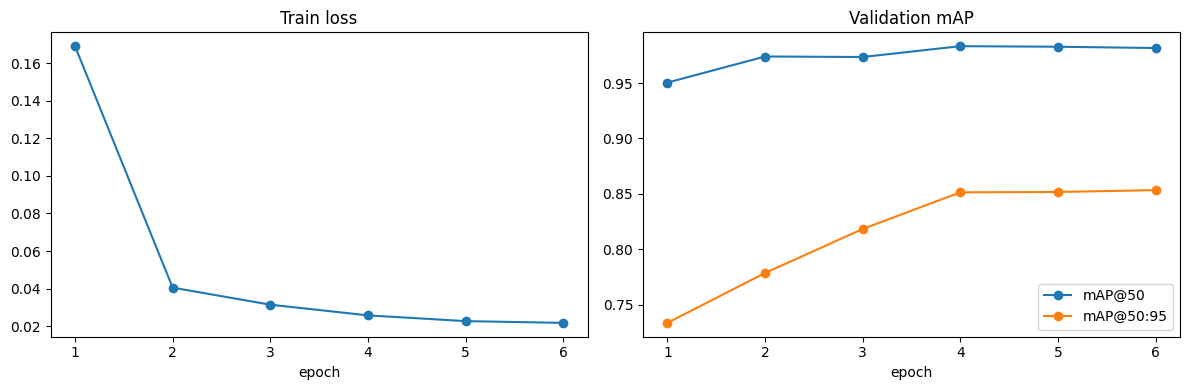

In [10]:
# ---- Train (resumes from Drive checkpoint if one exists) ----
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
total_it = EPOCHS * len(train_loader)
warm = min(300, len(train_loader))
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda it: (it + 1) / warm if it < warm else 0.5 * (1 + math.cos(math.pi * (it - warm) / max(1, total_it - warm))))
scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")

ckpt_last, ckpt_best = os.path.join(OUT, "last.pt"), os.path.join(OUT, "best.pt")
start_ep, history, best = 0, [], -1.0
if os.path.exists(ckpt_last):
    ck = torch.load(ckpt_last, map_location=dev, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    scaler.load_state_dict(ck["scaler"]); start_ep, history, best = ck["epoch"] + 1, ck["history"], ck["best"]
    print(f"Resumed from epoch {start_ep}")

for ep in range(start_ep, EPOCHS):
    model.train(); t0 = time.time(); run = defaultdict(float)
    for it, (imgs, tgts) in enumerate(train_loader):
        imgs = [im.to(dev) for im in imgs]
        tgts = [{k: v.to(dev) for k, v in t.items()} for t in tgts]
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            losses = model(imgs, tgts)
            loss = sum(losses.values())
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        for k, v in losses.items():
            run[k] += v.item()
        run["total"] += loss.item()
        if it % 50 == 0:
            print(f"ep {ep + 1} it {it}/{len(train_loader)} loss {loss.item():.3f} lr {opt.param_groups[0]['lr']:.5f}")
    m = coco_metrics(predict(model, val_ds), val_gt)
    rec = {"epoch": ep + 1, "time_s": time.time() - t0, **{k: v / len(train_loader) for k, v in run.items()},
           "val_mAP50": m["mAP50"], "val_mAP50_95": m["mAP50_95"]}
    history.append(rec)
    print(f"== epoch {ep + 1}: loss {rec['total']:.3f} | val mAP50 {m['mAP50']:.3f} | mAP50:95 {m['mAP50_95']:.3f} | {rec['time_s']:.0f}s")
    if m["mAP50_95"] > best:
        best = m["mAP50_95"]; torch.save(model.state_dict(), ckpt_best)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": ep, "history": history, "best": best}, ckpt_last)

json.dump(history, open(os.path.join(OUT, "history.json"), "w"), indent=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot([h["epoch"] for h in history], [h["total"] for h in history], "o-"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot([h["epoch"] for h in history], [h["val_mAP50"] for h in history], "o-", label="mAP@50")
ax[1].plot([h["epoch"] for h in history], [h["val_mAP50_95"] for h in history], "o-", label="mAP@50:95")
ax[1].set_title("Validation mAP"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "training.png"), dpi=120); plt.show()

In [11]:
# ---- Test-set COCO metrics with the best checkpoint ----
model.load_state_dict(torch.load(ckpt_best, map_location=dev))
test_preds = predict(model, test_ds)
test_m = coco_metrics(test_preds, test_gt, verbose=True)
print("Per-class AP:")
for n, v in test_m["per_class"].items():
    print(f"  {n:15s} AP50 {v['AP50']:.3f}  AP50:95 {v['AP50_95']:.3f}")

# Inference speed (batch 1)
model.eval(); sub = [test_ds[i][0].to(dev) for i in range(min(100, len(test_ds)))]
with torch.no_grad():
    for im in sub[:10]:
        model([im])
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for im in sub:
        model([im])
    if dev.type == "cuda": torch.cuda.synchronize()
fps = len(sub) / (time.time() - t0)
print(f"Inference: {fps:.1f} FPS (batch 1, fp32)")

Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.71s).
Accumulating evaluation results...
DONE (t=0.22s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.867
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.975
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.975
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.811
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.875
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.919
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.921
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.921
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1


[class_agnostic] test batteries: 705
  Missed-battery rate @ precision>=0.9: 0.000 (thr 0.01, precision 0.911, missed 0 of 705)
  Cost-weighted error (miss=10x FA), best thr 0.45: 0.000 per battery (FN 0, FP 0)

[class_aware] test batteries: 705
  Missed-battery rate @ precision>=0.9: 0.021 (thr 0.1, precision 0.902, missed 15 of 705)
  Cost-weighted error (miss=10x FA), best thr 0.12: 0.318 per battery (FN 16, FP 64)

Per-class miss rate at operating threshold 0.01: {'cylindric': 0.0, 'pouch': 0.0, 'prismatic': 0.0}


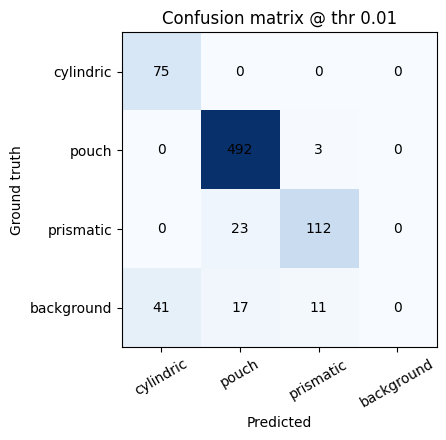

ECE (boxes with score >= 0.05): 0.036


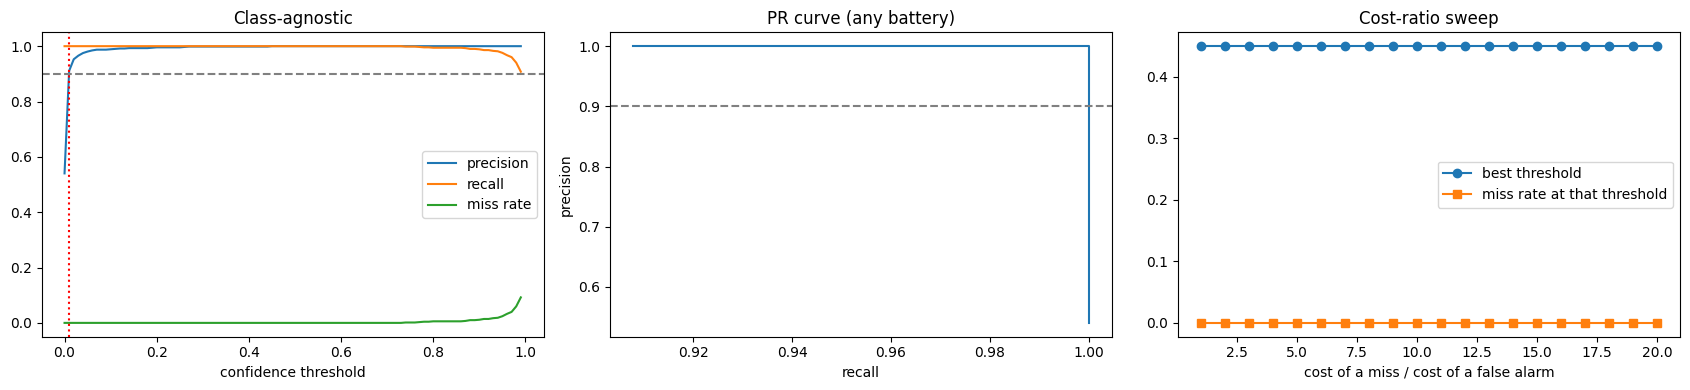

In [12]:
# ---- Safety metrics: missed-battery rate, cost-weighted error, confusion matrix ----
from torchvision.ops import box_iou, nms

def greedy_match(preds, ds, class_aware):
    """Greedy score-ordered matching per image. Because matching is greedy in score order, the result at
    any threshold t equals keeping only predictions with score >= t, so one pass serves the whole sweep.
    Class-agnostic mode asks 'was this battery detected at all?' and applies class-agnostic NMS first so a
    box predicted as two classes is not counted as an extra false alarm."""
    S, TP, PL, GL = [], [], [], []        # per prediction: score, matched?, pred label, matched gt label (0 if none)
    n_gt, gt_cls = 0, Counter()
    for iid in ds.ids:
        gb, gl = ds.gt(iid); n_gt += len(gb); gt_cls.update(gl.tolist())
        p = preds[iid]; pb, ps, pl = torch.from_numpy(p["boxes"]), torch.from_numpy(p["scores"]), p["labels"]
        if not class_aware and len(pb):
            keep = nms(pb, ps, 0.5); pb, ps, pl = pb[keep], ps[keep], pl[keep.numpy()]
        order = torch.argsort(ps, descending=True).numpy()
        ious = box_iou(pb, torch.from_numpy(gb)).numpy() if len(gb) and len(pb) else np.zeros((len(pb), len(gb)))
        used = np.zeros(len(gb), bool)
        for j in order:
            cand = ious[j].copy(); cand[used] = -1
            if class_aware:
                cand[gl != pl[j]] = -1
            k = int(cand.argmax()) if len(gb) else -1
            hit = k >= 0 and cand[k] >= IOU_MATCH
            if hit:
                used[k] = True
            S.append(float(ps[j])); TP.append(hit); PL.append(int(pl[j])); GL.append(int(gl[k]) if hit else 0)
    return np.array(S), np.array(TP, bool), np.array(PL), np.array(GL), n_gt, gt_cls

def sweep(S, TP, n_gt, ths):
    rows = []
    for t in ths:
        k = S >= t; tp = int(TP[k].sum()); fp = int(k.sum() - tp); fn = n_gt - tp
        rows.append({"thr": float(t), "tp": tp, "fp": fp, "fn": fn,
                     "precision": tp / max(tp + fp, 1), "recall": tp / max(n_gt, 1), "miss_rate": fn / max(n_gt, 1)})
    return rows

ths = np.round(np.linspace(0.0, 0.99, 100), 2)
safety = {}
for mode in ["class_agnostic", "class_aware"]:
    S, TP, PL, GL, n_gt, gt_cls = greedy_match(test_preds, test_ds, class_aware=(mode == "class_aware"))
    rows = sweep(S, TP, n_gt, ths)
    ok = [r for r in rows if r["precision"] >= TARGET_PRECISION]
    at_p = min(ok, key=lambda r: r["miss_rate"]) if ok else None
    cost_rows = {c: min(rows, key=lambda r: (c * r["fn"] + r["fp"]) / n_gt) for c in range(1, 21)}
    safety[mode] = {"rows": rows, "at_precision": at_p, "cost": cost_rows, "S": S, "TP": TP, "PL": PL, "GL": GL,
                    "n_gt": n_gt, "gt_cls": gt_cls}
    print(f"\n[{mode}] test batteries: {n_gt}")
    if at_p:
        print(f"  Missed-battery rate @ precision>={TARGET_PRECISION}: {at_p['miss_rate']:.3f} "
              f"(thr {at_p['thr']}, precision {at_p['precision']:.3f}, missed {at_p['fn']} of {n_gt})")
    else:
        print(f"  Precision never reaches {TARGET_PRECISION}")
    c10 = cost_rows[MISS_COST]
    print(f"  Cost-weighted error (miss={MISS_COST}x FA), best thr {c10['thr']}: "
          f"{(MISS_COST * c10['fn'] + c10['fp']) / n_gt:.3f} per battery (FN {c10['fn']}, FP {c10['fp']})")

# Per-class miss rate (class-agnostic detection) at the precision-0.90 threshold
A = safety["class_agnostic"]
thr_op = A["at_precision"]["thr"] if A["at_precision"] else 0.5
caught = Counter(A["GL"][(A["S"] >= thr_op) & A["TP"]].tolist())
per_class_miss = {CLASSES[c]: 1 - caught.get(c, 0) / A["gt_cls"][c] for c in range(1, K + 1) if A["gt_cls"][c]}
print(f"\nPer-class miss rate at operating threshold {thr_op}:", {k: round(v, 3) for k, v in per_class_miss.items()})

# Confusion matrix at the operating threshold (rows = ground truth, cols = prediction, last = background)
cm = np.zeros((K + 1, K + 1), int)
k = A["S"] >= thr_op
for hit, pl, gl in zip(A["TP"][k], A["PL"][k], A["GL"][k]):
    if hit: cm[gl - 1, pl - 1] += 1
    else:   cm[K, pl - 1] += 1                    # false alarm
for c in range(1, K + 1):
    cm[c - 1, K] = A["gt_cls"][c] - cm[c - 1, :K].sum()   # missed
labels = CLASSES[1:] + ["background"]
fig, ax = plt.subplots(figsize=(5.5, 4.5)); ax.imshow(cm, cmap="Blues")
for i in range(K + 1):
    for j in range(K + 1):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
ax.set_xticks(range(K + 1)); ax.set_xticklabels(labels, rotation=30); ax.set_yticks(range(K + 1)); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth"); ax.set_title(f"Confusion matrix @ thr {thr_op}")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "confusion_matrix.png"), dpi=120); plt.show()

# Expected calibration error (class-aware: is a box with confidence p correct p% of the time?)
C = safety["class_aware"]; keep = C["S"] >= 0.05; s, y = C["S"][keep], C["TP"][keep].astype(float)
bins = np.linspace(0.05, 1, 11); ece = 0.0
for lo, hi in zip(bins[:-1], bins[1:]):
    b = (s >= lo) & (s < hi)
    if b.any(): ece += b.mean() * abs(y[b].mean() - s[b].mean())
print(f"ECE (boxes with score >= 0.05): {ece:.3f}")

# Plots: precision/recall vs threshold, PR curve, cost-ratio sweep
R = A["rows"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(ths, [r["precision"] for r in R], label="precision"); ax[0].plot(ths, [r["recall"] for r in R], label="recall")
ax[0].plot(ths, [r["miss_rate"] for r in R], label="miss rate"); ax[0].axhline(TARGET_PRECISION, ls="--", c="gray")
ax[0].axvline(thr_op, ls=":", c="red"); ax[0].set_xlabel("confidence threshold"); ax[0].legend(); ax[0].set_title("Class-agnostic")
ax[1].plot([r["recall"] for r in R], [r["precision"] for r in R]); ax[1].axhline(TARGET_PRECISION, ls="--", c="gray")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("PR curve (any battery)")
cs = list(range(1, 21))
ax[2].plot(cs, [A["cost"][c]["thr"] for c in cs], "o-", label="best threshold")
ax[2].plot(cs, [A["cost"][c]["miss_rate"] for c in cs], "s-", label="miss rate at that threshold")
ax[2].set_xlabel("cost of a miss / cost of a false alarm"); ax[2].legend(); ax[2].set_title("Cost-ratio sweep")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "safety.png"), dpi=120); plt.show()

In [13]:
# ---- Save everything for the report ----
def strip(d):
    return {k: v for k, v in d.items() if k not in ("S", "TP", "PL", "GL", "gt_cls")}
results = {
    "model": "Faster R-CNN ResNet-50-FPN (COCO-pretrained, torchvision)", "epochs": EPOCHS, "batch": BATCH_SIZE,
    "lr": LR, "img_size": IMG_SIZE, "seed": SEED, "split_mode": SPLIT_MODE, "eda": eda,
    "params_M": n_params / 1e6, "fps_batch1": fps, "test_coco": test_m, "ece": ece,
    "operating_threshold": thr_op, "per_class_miss_rate": per_class_miss, "confusion_matrix": cm.tolist(),
    "safety": {m: strip(v) for m, v in safety.items()},
}
json.dump(results, open(os.path.join(OUT, "results.json"), "w"), indent=1, default=float)

A_at = A["at_precision"]; c10 = A["cost"][MISS_COST]
print("\n================ SUMMARY FOR THE REPORT ================")
print(f"Split: {SPLIT_MODE} | train {len(train_ds)} / val {len(val_ds)} / test {len(test_ds)} images")
print(f"Test mAP@50: {test_m['mAP50']:.3f} | mAP@50:95: {test_m['mAP50_95']:.3f}")
for n, v in test_m["per_class"].items():
    print(f"  AP50 {n}: {v['AP50']:.3f}")
if A_at:
    print(f"Missed-battery rate @ P>={TARGET_PRECISION}: {A_at['miss_rate']:.3f} ({A_at['fn']}/{A['n_gt']} missed, thr {A_at['thr']})")
print(f"Cost-weighted error @ {MISS_COST}:1: {(MISS_COST * c10['fn'] + c10['fp']) / A['n_gt']:.3f} per battery (thr {c10['thr']})")
print(f"Per-class miss rate: {({k: round(v, 3) for k, v in per_class_miss.items()})}")
print(f"ECE: {ece:.3f} | Params: {n_params / 1e6:.1f} M | FPS: {fps:.1f}")
print(f"Files saved in {OUT}")

# Zip results + figures (not the large .pt checkpoints) and download them to this computer
import shutil
pack = "/content/frcnn_results" if os.path.isdir("/content") else "./frcnn_results"
os.makedirs(pack, exist_ok=True)
for f in ["results.json", "history.json", "split.json"]:
    if os.path.exists(os.path.join(OUT, f)):
        shutil.copy(os.path.join(OUT, f), pack)
shutil.copytree(FIG, os.path.join(pack, "figures"), dirs_exist_ok=True)
zip_path = shutil.make_archive(pack, "zip", pack)
print("Results zip:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass


================ SUMMARY FOR THE REPORT ================
Split: grouped by battery ID | train 1421 / val 702 / test 705 images
Test mAP@50: 0.975 | mAP@50:95: 0.867
  AP50 cylindric: 1.000
  AP50 pouch: 0.990
  AP50 prismatic: 0.934
Missed-battery rate @ P>=0.9: 0.000 (0/705 missed, thr 0.01)
Cost-weighted error @ 10:1: 0.000 per battery (thr 0.45)
Per-class miss rate: {'cylindric': 0.0, 'pouch': 0.0, 'prismatic': 0.0}
ECE: 0.036 | Params: 41.3 M | FPS: 10.8
Files saved in /content/drive/MyDrive/dont_miss_the_battery/frcnn_baseline_v2
Results zip: /content/frcnn_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>